
**Limitations to state in the README:** self-reported survey data, one year (2015), US population, target mixes prediabetes and diabetes, results are not medical advice.

# Healora
**Goal:** Understanding and documenting the data before any modelling.

**Data:** CDC Behavioral Risk Factor Surveillance System (BRFSS) 2015, as prepared in the *CDC Diabetes Health Indicators* dataset (UCI / Kaggle). Source attribution only: this project is not endorsed by the CDC. The licence of the prepared file was not independently verified (listed as CC0 on Kaggle), so the CSV is **not** redistributed in this repository.

**Target:** `Diabetes_binary` = survey-reported status, `0` = no diabetes, `1` = prediabetes or diabetes. This is classification of *self-reported current status*, not a diagnosis and not a prediction of future diabetes.

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs("figures", exist_ok=True)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/health diabetes diagnosis/cdc_diabetes_health_indicators.csv")

print(df.head())
print(df.head(10))

   ID  Diabetes_binary  HighBP  HighChol  CholCheck  BMI  Smoker  Stroke  \
0   0                0       1         1          1   40       1       0   
1   1                0       0         0          0   25       1       0   
2   2                0       1         1          1   28       0       0   
3   3                0       1         0          1   27       0       0   
4   4                0       1         1          1   24       0       0   

   HeartDiseaseorAttack  PhysActivity  ...  AnyHealthcare  NoDocbcCost  \
0                     0             0  ...              1            0   
1                     0             1  ...              0            1   
2                     0             0  ...              1            1   
3                     0             1  ...              1            0   
4                     0             1  ...              1            0   

   GenHlth  MentHlth  PhysHlth  DiffWalk  Sex  Age  Education  Income  
0        5        18      

## Structure, types and missing values

In [ ]:
print(df.dtypes.value_counts())
print("Missing values:", int(df.isna().sum().sum()))
print("ID is a simple row counter:", (df.ID == np.arange(len(df))).all())

int64    23
Name: count, dtype: int64
Missing values: 0
ID is a simple row counter: True


`ID` is only a row counter, so it carries no information and **must be dropped** before modelling. There are no missing values.

In [ ]:
X = df.drop(columns="ID")
X.describe().T[["min", "max", "mean"]].round(2)

,min,max,mean
Diabetes_binary,0.0,1.0,0.14
HighBP,0.0,1.0,0.43
HighChol,0.0,1.0,0.42
CholCheck,0.0,1.0,0.96
BMI,12.0,98.0,28.38
Smoker,0.0,1.0,0.44
Stroke,0.0,1.0,0.04
HeartDiseaseorAttack,0.0,1.0,0.09
PhysActivity,0.0,1.0,0.76
Fruits,0.0,1.0,0.63


## Class balance

Positive class (diabetes/prediabetes): 13.9%
Majority-class baseline accuracy: 86.1%


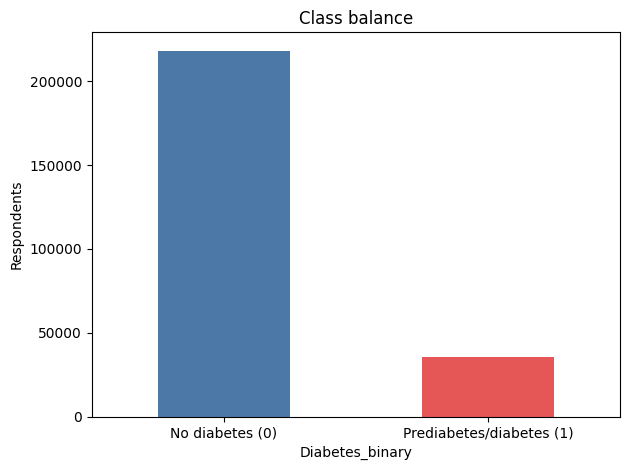

In [ ]:
rate = X.Diabetes_binary.mean()
print(f"Positive class (diabetes/prediabetes): {rate:.1%}")
print(f"Majority-class baseline accuracy: {1-rate:.1%}")
ax = X.Diabetes_binary.value_counts().sort_index().plot(kind="bar", color=["#4C78A8", "#E45756"])
ax.set_xticklabels(["No diabetes (0)", "Prediabetes/diabetes (1)"], rotation=0)
ax.set_ylabel("Respondents"); ax.set_title("Class balance")
plt.tight_layout(); plt.savefig("figures/class_balance.png", dpi=150); plt.show()

**Finding:** about 14% are positive. A model that predicts 'no diabetes' for everyone would already be **86% accurate**, so accuracy is a misleading metric here. We will judge models by recall, precision, F1 and PR-AUC against this baseline.

## Handling Duplicates

In [ ]:
dup = X.duplicated()
print(f"Duplicate rows (ignoring ID): {dup.sum():,} ({dup.mean():.2%})")
allcopies = X[X.duplicated(keep=False)]
print(f"Positive rate among duplicated rows: {allcopies.Diabetes_binary.mean():.1%} (overall {rate:.1%})")
print(f"Positive rate after dropping duplicates: {X.drop_duplicates().Diabetes_binary.mean():.1%}")

Duplicate rows (ignoring ID): 24,206 (9.54%)
Positive rate among duplicated rows: 1.3% (overall 13.9%)
Positive rate after dropping duplicates: 15.3%


**Finding:** 24,206 rows (9.5%) are exact copies of another row once `ID` is ignored (the `ID` column hid them). This does not necessarily mean data errors: with mostly yes/no and coarse-band answers, many different healthy respondents can give identical answers. But duplicated profiles are overwhelmingly **non-diabetic** (1.3% positive), so they affect the class balance and can place identical rows in both train and test.

**Decision (to confirm):** keep the data for the main model, make sure evaluation is not inflated by identical rows, and run a **sensitivity check** with duplicates removed.

## 4. Odd values and ranges

0.001    16.0
0.010    18.0
0.500    27.0
0.990    50.0
0.999    81.0
Name: BMI, dtype: float64
BMI > 60: 805 | BMI < 15: 68 | max: 98


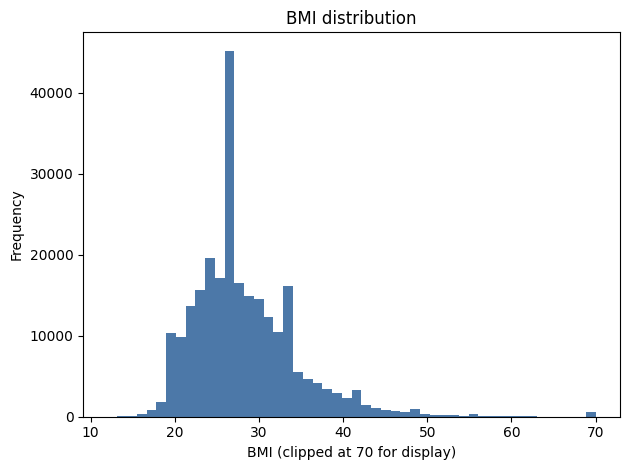

In [ ]:
print(X.BMI.quantile([.001, .01, .5, .99, .999]))
print("BMI > 60:", int((X.BMI > 60).sum()), "| BMI < 15:", int((X.BMI < 15).sum()), "| max:", X.BMI.max())
X.BMI.clip(upper=70).plot(kind="hist", bins=50, color="#4C78A8")
plt.xlabel("BMI (clipped at 70 for display)"); plt.title("BMI distribution")
plt.tight_layout(); plt.savefig("figures/bmi.png", dpi=150); plt.show()

BMI is self-reported and has extreme values (up to 98; 805 respondents above 60). These are probably reporting errors. We will handle them in preprocessing (for example capping), not silently delete them.

## Coding of the other variables
Many columns are **coded categories, not raw measurements**, so they must not be read as plain numbers:
- `Age`: 13 age bands (1 = 18-24 ... 13 = 80+), not years.
- `GenHlth`: self-rated health 1 (excellent) to 5 (poor). `Education`: 1-6. `Income`: 1-8 bands.
- `MentHlth`, `PhysHlth`: number of unhealthy days in the last 30.
- Everything else is yes/no (0/1), including `Sex` (see the dataset documentation for the coding).

## First look at what is related to the target

GenHlth                 0.294
HighBP                  0.263
DiffWalk                0.218
BMI                     0.217
HighChol                0.200
Age                     0.177
HeartDiseaseorAttack    0.177
PhysHlth                0.171
Name: Diabetes_binary, dtype: float64


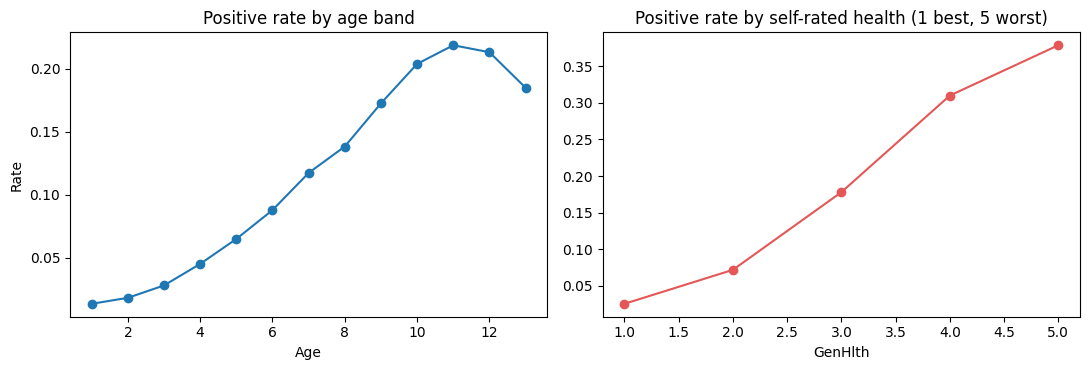

In [ ]:
corr = X.corr()["Diabetes_binary"].drop("Diabetes_binary").sort_values(key=abs, ascending=False)
print(corr.head(8).round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
X.groupby("Age").Diabetes_binary.mean().plot(ax=ax[0], marker="o")
ax[0].set_title("Positive rate by age band"); ax[0].set_ylabel("Rate")
X.groupby("GenHlth").Diabetes_binary.mean().plot(ax=ax[1], marker="o", color="#E45756")
ax[1].set_title("Positive rate by self-rated health (1 best, 5 worst)")
plt.tight_layout(); plt.savefig("figures/rate_by_age_health.png", dpi=150); plt.show()

In [ ]:

# Step 1: Understand our target variable

target = "Diabetes_binary"

print("Target class counts:")
print(df[target].value_counts().sort_index())

print("\nTarget class percentages:")
print((df[target].value_counts(normalize=True).sort_index() * 100).round(2))

print("\nMissing values in target:", df[target].isna().sum())


Target class counts:
Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64

Target class percentages:
Diabetes_binary
0    86.07
1    13.93
Name: proportion, dtype: float64

Missing values in target: 0


In [ ]:

# Step 2: Prepare the data and build a baseline

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Separate input features (X) and target (y)
target = "Diabetes_binary"

X = df.drop(columns=[target, "ID"], errors="ignore")
y = df[target].astype(int)

# Split into training data (80%) and test data (20%)
# Stratification preserves approximately the same class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of input features:", X_train.shape[1])

# Create a simple majority-class baseline
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)

# Evaluate baseline performance
print("\nBASELINE MODEL RESULTS")
print("Accuracy:", round(accuracy_score(y_test, y_pred_baseline), 4))
print("Precision:", round(precision_score(
    y_test, y_pred_baseline, zero_division=0
), 4))
print("Recall:", round(recall_score(
    y_test, y_pred_baseline, zero_division=0
), 4))
print("F1-score:", round(f1_score(
    y_test, y_pred_baseline, zero_division=0
), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_baseline))


Training records: 202944
Testing records: 50736
Number of input features: 21

BASELINE MODEL RESULTS
Accuracy: 0.8607
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Confusion matrix:
[[43667     0]
 [ 7069     0]]


In [ ]:

# Step 3: Train our first real ML model

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    classification_report
)

# Build the model pipeline
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

# Train on the training data
log_reg.fit(X_train, y_train)

# Make predictions on the test data
y_pred_lr = log_reg.predict(X_test)

# Estimate probability of class 1
y_prob_lr = log_reg.predict_proba(X_test)[:, 1]

# Evaluate the model
print("LOGISTIC REGRESSION RESULTS")

print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_lr, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_lr, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))


LOGISTIC REGRESSION RESULTS
Accuracy: 0.8621
Precision: 0.5171
Recall: 0.1583
F1-score: 0.2424
ROC-AUC: 0.8192

Confusion matrix:
[[42622  1045]
 [ 5950  1119]]

Classification report:
              precision    recall  f1-score   support

           0       0.88      0.98      0.92     43667
           1       0.52      0.16      0.24      7069

    accuracy                           0.86     50736
   macro avg       0.70      0.57      0.58     50736
weighted avg       0.83      0.86      0.83     50736



## Tried Logistic Regression with balanced class weights

In [ ]:

# Step 4:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Split ONLY the existing training data into training and validation sets
X_train_fit, X_val, y_train_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Create a balanced Logistic Regression pipeline
log_reg_balanced = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

# Train the model
log_reg_balanced.fit(X_train_fit, y_train_fit)

# Predict on validation data
y_val_pred = log_reg_balanced.predict(X_val)
y_val_prob = log_reg_balanced.predict_proba(X_val)[:, 1]

# Evaluate validation performance
print("BALANCED LOGISTIC REGRESSION — VALIDATION RESULTS")

print("Accuracy:", round(accuracy_score(y_val, y_val_pred), 4))
print("Precision:", round(precision_score(y_val, y_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_val_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_val, y_val_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_prob), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_val, y_val_pred))


BALANCED LOGISTIC REGRESSION — VALIDATION RESULTS
Accuracy: 0.7314
Precision: 0.3107
Recall: 0.7613
F1-score: 0.4412
ROC-AUC: 0.8212

Confusion matrix:
[[25381  9553]
 [ 1350  4305]]


In [ ]:

# Step 5: Fair comparison on the same validation set

import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# Train ordinary Logistic Regression using the same training subset
log_reg_unbalanced = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

log_reg_unbalanced.fit(X_train_fit, y_train_fit)

# Predictions from both models on the SAME validation set
pred_unbalanced = log_reg_unbalanced.predict(X_val)
prob_unbalanced = log_reg_unbalanced.predict_proba(X_val)[:, 1]

pred_balanced = log_reg_balanced.predict(X_val)
prob_balanced = log_reg_balanced.predict_proba(X_val)[:, 1]

def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

comparison = pd.DataFrame([
    evaluate_model(
        "Unbalanced Logistic Regression",
        y_val, pred_unbalanced, prob_unbalanced
    ),
    evaluate_model(
        "Balanced Logistic Regression",
        y_val, pred_balanced, prob_balanced
    )
])

print(comparison.round(4).to_string(index=False))


                         Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
Unbalanced Logistic Regression    0.8636     0.5353  0.1595    0.2458   0.8208
  Balanced Logistic Regression    0.7314     0.3107  0.7613    0.4412   0.8212


In [ ]:

# Step 5: Fair comparison on the same validation set

import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# Train ordinary Logistic Regression using the same training subset
log_reg_unbalanced = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

log_reg_unbalanced.fit(X_train_fit, y_train_fit)

# Predictions from both models on the SAME validation set
pred_unbalanced = log_reg_unbalanced.predict(X_val)
prob_unbalanced = log_reg_unbalanced.predict_proba(X_val)[:, 1]

pred_balanced = log_reg_balanced.predict(X_val)
prob_balanced = log_reg_balanced.predict_proba(X_val)[:, 1]

def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

comparison = pd.DataFrame([
    evaluate_model(
        "Unbalanced Logistic Regression",
        y_val, pred_unbalanced, prob_unbalanced
    ),
    evaluate_model(
        "Balanced Logistic Regression",
        y_val, pred_balanced, prob_balanced
    )
])

print(comparison.round(4).to_string(index=False))


                         Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
Unbalanced Logistic Regression    0.8636     0.5353  0.1595    0.2458   0.8208
  Balanced Logistic Regression    0.7314     0.3107  0.7613    0.4412   0.8212


## Trained a Random Forest classifier

In [ ]:

# Step 6:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Create the model
rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=18,
    min_samples_leaf=5,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

# Train using the training subset only
rf_model.fit(X_train_fit, y_train_fit)

# Predict on the same validation set used for Logistic Regression
y_val_pred_rf = rf_model.predict(X_val)
y_val_prob_rf = rf_model.predict_proba(X_val)[:, 1]

# Evaluate the model
print("RANDOM FOREST — VALIDATION RESULTS")

print("Accuracy:", round(accuracy_score(y_val, y_val_pred_rf), 4))
print("Precision:", round(precision_score(
    y_val, y_val_pred_rf, zero_division=0
), 4))
print("Recall:", round(recall_score(
    y_val, y_val_pred_rf, zero_division=0
), 4))
print("F1-score:", round(f1_score(
    y_val, y_val_pred_rf, zero_division=0
), 4))
print("ROC-AUC:", round(roc_auc_score(
    y_val, y_val_prob_rf
), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))

print("\nClassification report:")
print(classification_report(
    y_val, y_val_pred_rf, zero_division=0
))


RANDOM FOREST — VALIDATION RESULTS
Accuracy: 0.8671
Precision: 0.6058
Recall: 0.1326
F1-score: 0.2176
ROC-AUC: 0.8245

Confusion matrix:
[[34446   488]
 [ 4905   750]]

Classification report:
              precision    recall  f1-score   support

           0       0.88      0.99      0.93     34934
           1       0.61      0.13      0.22      5655

    accuracy                           0.87     40589
   macro avg       0.74      0.56      0.57     40589
weighted avg       0.84      0.87      0.83     40589



## Visualise one decision tree inside our Random Forest

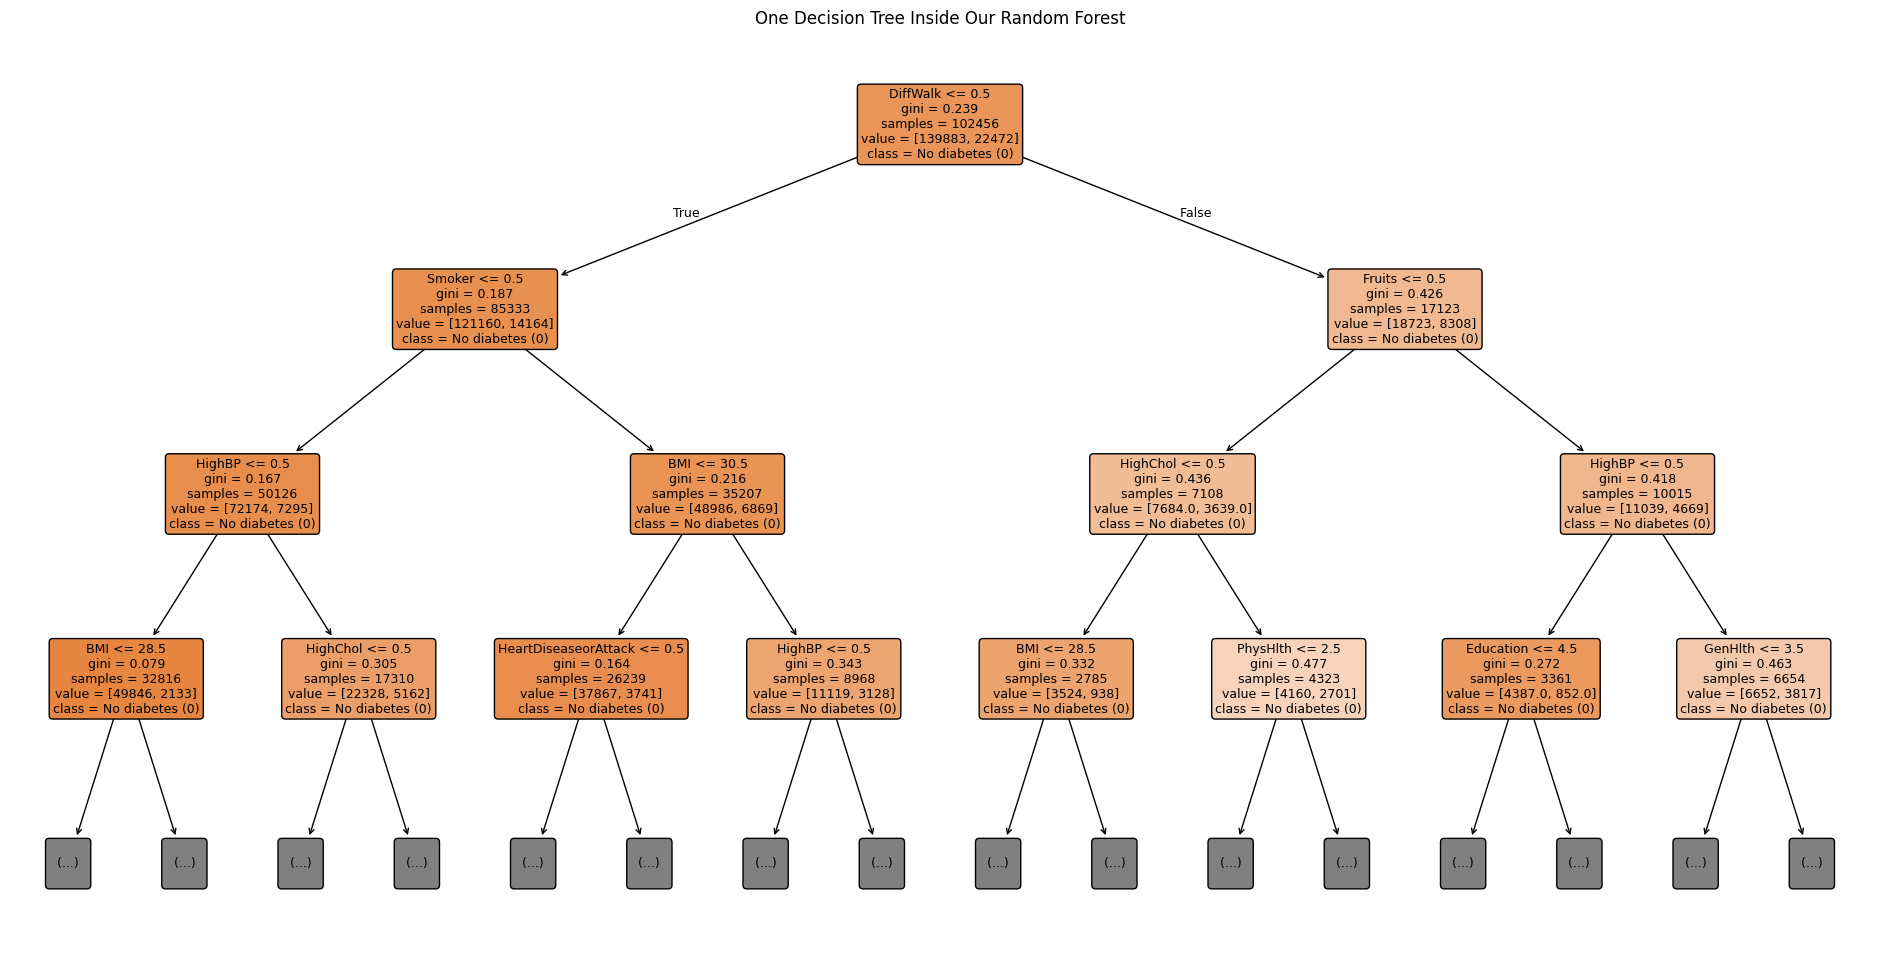

In [ ]:


import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Select the first of the 150 trees
one_tree = rf_model.estimators_[0]

plt.figure(figsize=(24, 12))

plot_tree(
    one_tree,
    max_depth=3,
    feature_names=X_train_fit.columns.tolist(),
    class_names=["No diabetes (0)", "Positive class (1)"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("One Decision Tree Inside Our Random Forest")
plt.show()


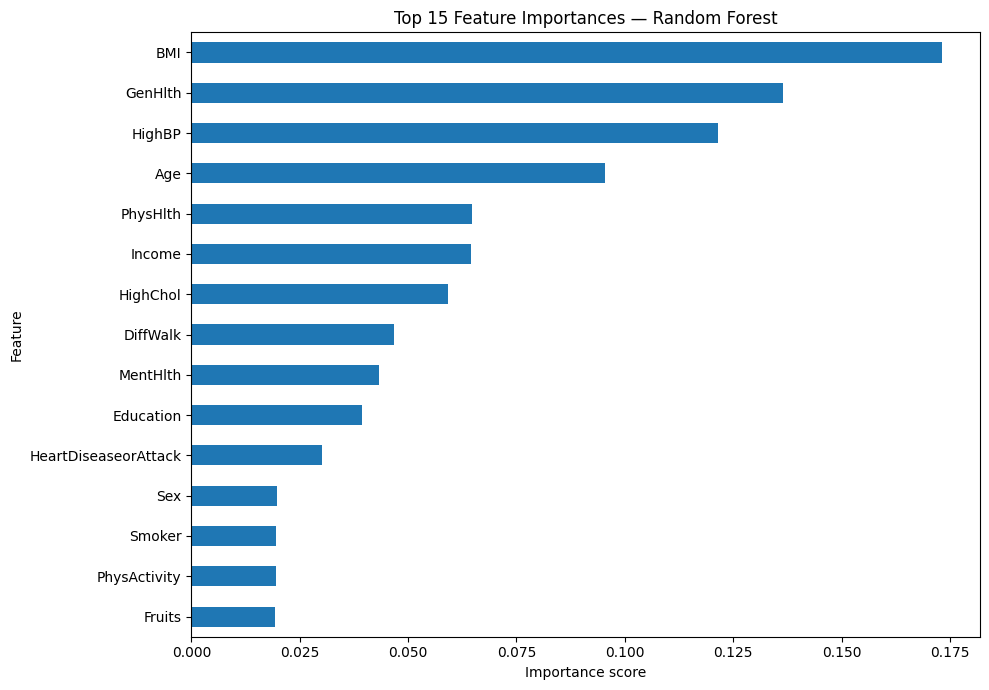

BMI                     0.1733
GenHlth                 0.1364
HighBP                  0.1215
Age                     0.0955
PhysHlth                0.0647
Income                  0.0646
HighChol                0.0592
DiffWalk                0.0467
MentHlth                0.0434
Education               0.0394
HeartDiseaseorAttack    0.0301
Sex                     0.0197
Smoker                  0.0196
PhysActivity            0.0195
Fruits                  0.0193
dtype: float64


In [ ]:

# Step 7: Visualise feature importance

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance scores from our trained Random Forest
importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train_fit.columns
).sort_values(ascending=True)

# Plot the 15 most important features
plt.figure(figsize=(10, 7))

importance.tail(15).plot(kind="barh")

plt.title("Top 15 Feature Importances — Random Forest")
plt.xlabel("Importance score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Display the actual values
print(importance.sort_values(ascending=False).head(15).round(4))


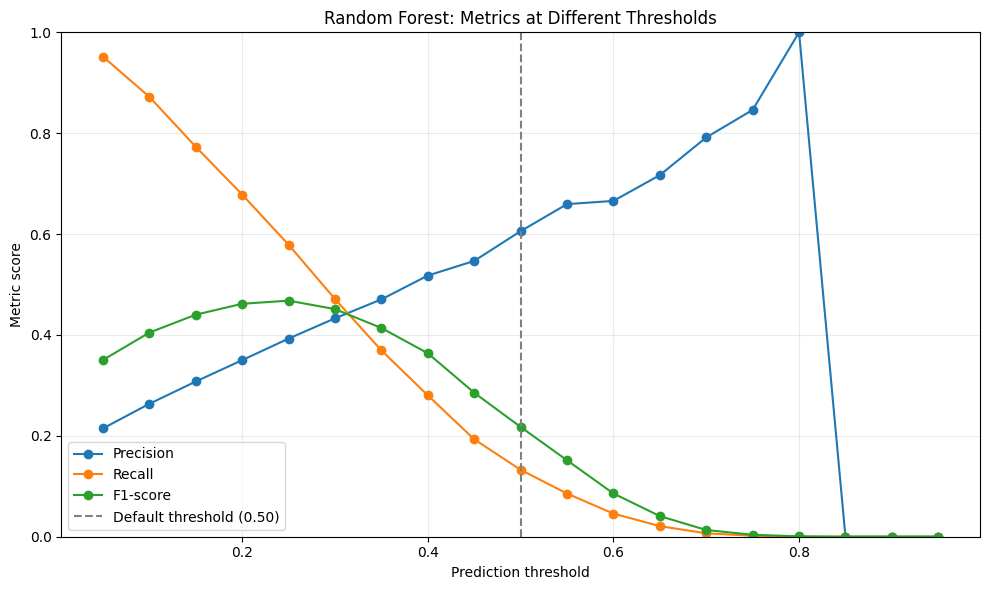

 Threshold  Precision  Recall  F1-score
      0.05      0.215   0.952     0.351
      0.10      0.264   0.872     0.405
      0.15      0.308   0.773     0.440
      0.20      0.350   0.678     0.462
      0.25      0.393   0.579     0.468
      0.30      0.433   0.471     0.451
      0.35      0.471   0.369     0.414
      0.40      0.518   0.280     0.364
      0.45      0.547   0.193     0.285
      0.50      0.606   0.133     0.218
      0.55      0.659   0.086     0.152
      0.60      0.666   0.046     0.086
      0.65      0.717   0.021     0.041
      0.70      0.792   0.007     0.013
      0.75      0.846   0.002     0.004
      0.80      1.000   0.000     0.001
      0.85      0.000   0.000     0.000
      0.90      0.000   0.000     0.000
      0.95      0.000   0.000     0.000


In [ ]:

# Step 8: Explore different prediction thresholds

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Use the Random Forest probabilities already calculated
# on our validation set: y_val_prob_rf

thresholds = np.arange(0.05, 0.96, 0.05)
results = []

for threshold in thresholds:
    # Convert probabilities into class predictions
    predictions = (y_val_prob_rf >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

# Plot precision and recall against the threshold
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1-score"],
    marker="o",
    label="F1-score"
)

plt.axvline(
    0.5, color="grey", linestyle="--",
    label="Default threshold (0.50)"
)

plt.xlabel("Prediction threshold")
plt.ylabel("Metric score")
plt.title("Random Forest: Metrics at Different Thresholds")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(threshold_results.round(3).to_string(index=False))


In [ ]:

# Step 9: Compare default and lower prediction thresholds

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)
import pandas as pd

threshold_comparison = []

for threshold in [0.50, 0.25, 0.20]:
    predictions = (y_val_prob_rf >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    threshold_comparison.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "True positives": tp,
        "False positives": fp,
        "False negatives": fn,
        "True negatives": tn
    })

comparison_df = pd.DataFrame(threshold_comparison)

print(comparison_df.round(4).to_string(index=False))


 Threshold  Accuracy  Precision  Recall  F1-score  True positives  False positives  False negatives  True negatives
      0.50    0.8671     0.6058  0.1326    0.2176             750              488             4905           34446
      0.25    0.8167     0.3929  0.5788    0.4680            3273             5058             2382           29876
      0.20    0.7798     0.3502  0.6782    0.4619            3835             7117             1820           27817


In [ ]:

# Step 10: Train a class-weighted Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import numpy as np
import pandas as pd

rf_balanced_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=18,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train on the same training subset as our previous models
rf_balanced_model.fit(X_train_fit, y_train_fit)

# Get probabilities for the positive class on validation data
y_val_prob_rf_balanced = rf_balanced_model.predict_proba(X_val)[:, 1]

# Compare several thresholds
thresholds = np.arange(0.05, 0.96, 0.05)
results = []

for threshold in thresholds:
    predictions = (y_val_prob_rf_balanced >= threshold).astype(int)

    results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

rf_balanced_results = pd.DataFrame(results)

print("TOP 5 THRESHOLDS BY VALIDATION F1-SCORE")
print(
    rf_balanced_results
    .sort_values("F1-score", ascending=False)
    .head(5)
    .round(4)
    .to_string(index=False)
)

print("\nROC-AUC:", round(
    roc_auc_score(y_val, y_val_prob_rf_balanced), 4
))


TOP 5 THRESHOLDS BY VALIDATION F1-SCORE
 Threshold  Precision  Recall  F1-score
      0.55     0.3824  0.5892    0.4638
      0.50     0.3550  0.6566    0.4608
      0.60     0.4115  0.5156    0.4577
      0.45     0.3282  0.7215    0.4512
      0.40     0.3029  0.7768    0.4359

ROC-AUC: 0.8229


## Compare threshold choices across all four models

In [ ]:

# Step 11:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Each model's probabilities come from the SAME validation set.
model_probabilities = {
    "Logistic Regression": prob_unbalanced,
    "Balanced Logistic Regression": prob_balanced,
    "Random Forest": y_val_prob_rf,
    "Balanced Random Forest": y_val_prob_rf_balanced
}

thresholds = np.arange(0.05, 0.951, 0.01)

best_results = []

for model_name, probabilities in model_probabilities.items():
    best_for_model = None

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        precision = precision_score(
            y_val, predictions, zero_division=0
        )
        recall = recall_score(
            y_val, predictions, zero_division=0
        )
        f1 = f1_score(
            y_val, predictions, zero_division=0
        )

        if best_for_model is None or f1 > best_for_model["F1-score"]:
            best_for_model = {
                "Model": model_name,
                "Threshold": threshold,
                "Precision": precision,
                "Recall": recall,
                "F1-score": f1,
                "ROC-AUC": roc_auc_score(y_val, probabilities)
            }

    best_results.append(best_for_model)

comparison = pd.DataFrame(best_results)

print("BEST VALIDATION F1-SCORE FOR EACH MODEL")
print(
    comparison
    .sort_values("F1-score", ascending=False)
    .round(4)
    .to_string(index=False)
)


BEST VALIDATION F1-SCORE FOR EACH MODEL
                       Model  Threshold  Precision  Recall  F1-score  ROC-AUC
               Random Forest       0.24     0.3860  0.6044    0.4711   0.8245
      Balanced Random Forest       0.54     0.3772  0.6048    0.4646   0.8229
Balanced Logistic Regression       0.66     0.3867  0.5703    0.4609   0.8212
         Logistic Regression       0.21     0.3681  0.6141    0.4603   0.8208


## Try HistGradientBoosting

In [ ]:

# Step 12:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Create the model
gb_model = HistGradientBoostingClassifier(
    learning_rate=0.1,
    max_iter=150,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

# Train on the same training subset as our other models
gb_model.fit(X_train_fit, y_train_fit)

# Predict probabilities on validation data
y_val_prob_gb = gb_model.predict_proba(X_val)[:, 1]

# Evaluate at the default threshold
y_val_pred_gb = (y_val_prob_gb >= 0.50).astype(int)

print("HIST GRADIENT BOOSTING — VALIDATION RESULTS")

print("Accuracy:", round(
    accuracy_score(y_val, y_val_pred_gb), 4
))
print("Precision:", round(
    precision_score(y_val, y_val_pred_gb, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_val, y_val_pred_gb, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_val, y_val_pred_gb, zero_division=0), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_val, y_val_prob_gb), 4
))

# Search thresholds on validation data
thresholds = np.arange(0.05, 0.951, 0.01)
threshold_results = []

for threshold in thresholds:
    predictions = (y_val_prob_gb >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

gb_threshold_df = pd.DataFrame(threshold_results)

best_gb = gb_threshold_df.loc[
    gb_threshold_df["F1-score"].idxmax()
]

print("\nBEST VALIDATION THRESHOLD")
print(best_gb.round(4).to_string())


HIST GRADIENT BOOSTING — VALIDATION RESULTS
Accuracy: 0.866
Precision: 0.5684
Recall: 0.1586
F1-score: 0.248
ROC-AUC: 0.8276

BEST VALIDATION THRESHOLD
Threshold    0.2400
Precision    0.3862
Recall       0.5988
F1-score     0.4696


## Final Random Forest evaluation

FINAL RANDOM FOREST — TEST RESULTS
 Threshold  Accuracy  Precision  Recall  F1-score
      0.24    0.8089     0.3802  0.5903    0.4625
      0.50    0.8659     0.5821  0.1328    0.2163

ROC-AUC: 0.8233
Average precision (PR-AUC summary): 0.4197

Confusion matrix at threshold 0.24:
[[36865  6802]
 [ 2896  4173]]

Classification report:
                    precision    recall  f1-score   support

   No diabetes (0)       0.93      0.84      0.88     43667
Positive class (1)       0.38      0.59      0.46      7069

          accuracy                           0.81     50736
         macro avg       0.65      0.72      0.67     50736
      weighted avg       0.85      0.81      0.83     50736



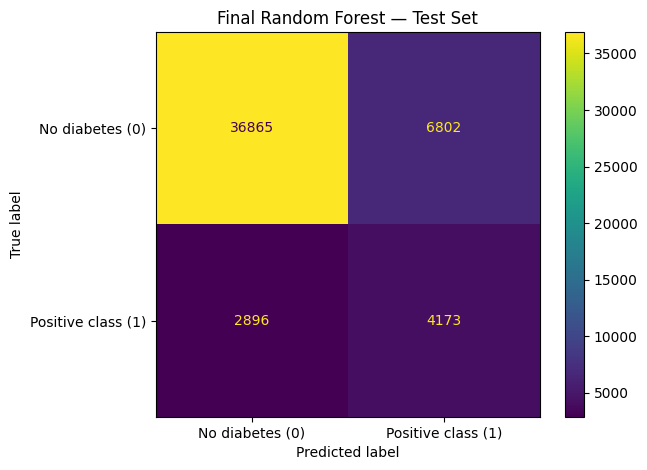

In [ ]:

# Step 13: Final Random Forest evaluation

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Train the selected model on the full training split
final_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=18,
    min_samples_leaf=5,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)

# 2. Get probability scores for the positive class
y_test_prob = final_model.predict_proba(X_test)[:, 1]

# 3. Compare the validation-selected threshold with the default
evaluation_results = []

for threshold in [0.24, 0.50]:
    predictions = (y_test_prob >= threshold).astype(int)

    evaluation_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

print("FINAL RANDOM FOREST — TEST RESULTS")
print(pd.DataFrame(evaluation_results).round(4).to_string(index=False))

# 4. Threshold-independent ranking metrics
print("\nROC-AUC:", round(
    roc_auc_score(y_test, y_test_prob), 4
))
print("Average precision (PR-AUC summary):", round(
    average_precision_score(y_test, y_test_prob), 4
))

# 5. Detailed evaluation using the selected threshold
selected_threshold = 0.24
y_test_pred = (y_test_prob >= selected_threshold).astype(int)

print(f"\nConfusion matrix at threshold {selected_threshold}:")
print(confusion_matrix(y_test, y_test_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["No diabetes (0)", "Positive class (1)"],
    zero_division=0
))

# 6. Visualise final confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=[0, 1],
    display_labels=["No diabetes (0)", "Positive class (1)"],
    values_format="d"
)

plt.title("Final Random Forest — Test Set")
plt.tight_layout()
plt.show()


## Compared ROC and Precision-Recall curves

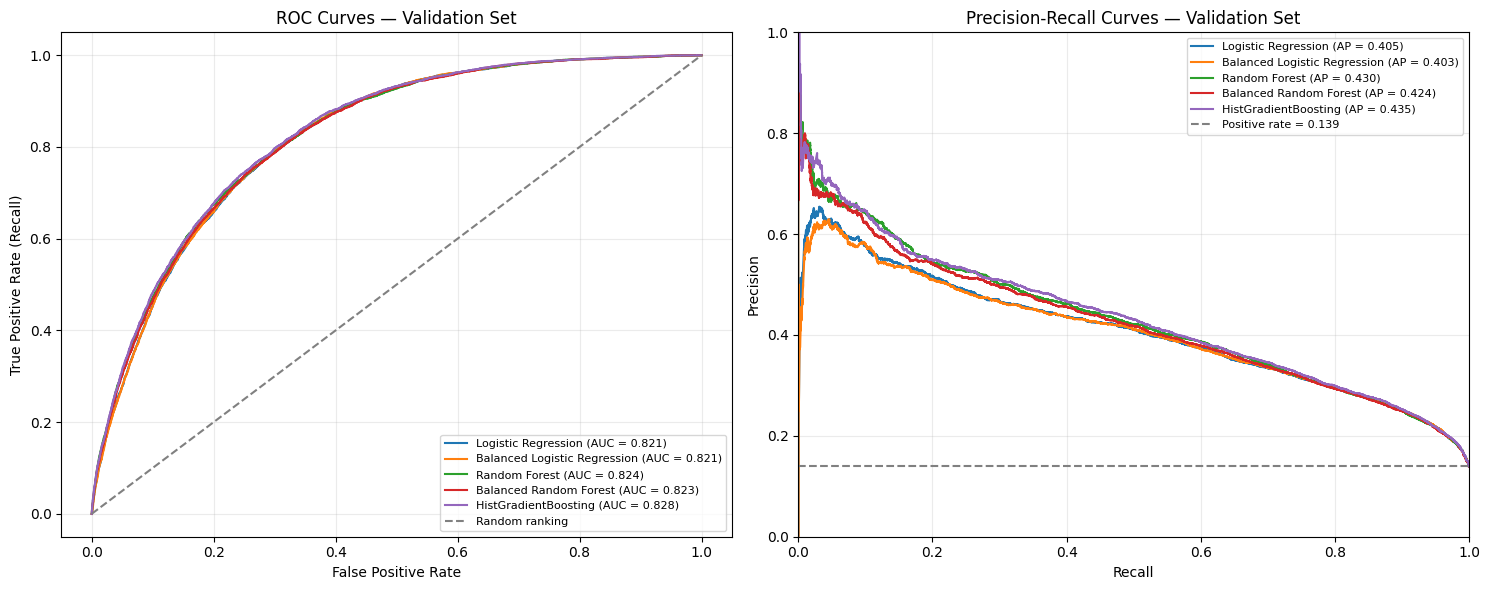

In [ ]:

# Step 14: Compare ROC and Precision-Recall curves

import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

model_probabilities = {
    "Logistic Regression": prob_unbalanced,
    "Balanced Logistic Regression": prob_balanced,
    "Random Forest": y_val_prob_rf,
    "Balanced Random Forest": y_val_prob_rf_balanced,
    "HistGradientBoosting": y_val_prob_gb
}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for name, probabilities in model_probabilities.items():

    # ROC curve
    fpr, tpr, _ = roc_curve(y_val, probabilities)
    auc_score = roc_auc_score(y_val, probabilities)

    axes[0].plot(
        fpr, tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

    # Precision-Recall curve
    precision, recall, _ = precision_recall_curve(
        y_val, probabilities
    )
    ap_score = average_precision_score(y_val, probabilities)

    axes[1].plot(
        recall, precision,
        label=f"{name} (AP = {ap_score:.3f})"
    )

# ROC reference line
axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--", color="grey",
    label="Random ranking"
)

# Precision-Recall reference: positive-class prevalence
axes[1].axhline(
    y_val.mean(),
    linestyle="--", color="grey",
    label=f"Positive rate = {y_val.mean():.3f}"
)

axes[0].set_title("ROC Curves — Validation Set")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.25)

axes[1].set_title("Precision-Recall Curves — Validation Set")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


# *Compared all models at their selected validation thresholds*

MODEL COMPARISON — VALIDATION SET
                       Model  Threshold  Precision  Recall  F1-score  ROC-AUC  Average Precision
         Logistic Regression       0.21     0.3681  0.6141    0.4603   0.8208             0.4053
Balanced Logistic Regression       0.66     0.3867  0.5703    0.4609   0.8212             0.4032
               Random Forest       0.24     0.3860  0.6044    0.4711   0.8245             0.4302
      Balanced Random Forest       0.54     0.3772  0.6048    0.4646   0.8229             0.4237
        HistGradientBoosting       0.24     0.3862  0.5988    0.4696   0.8276             0.4350


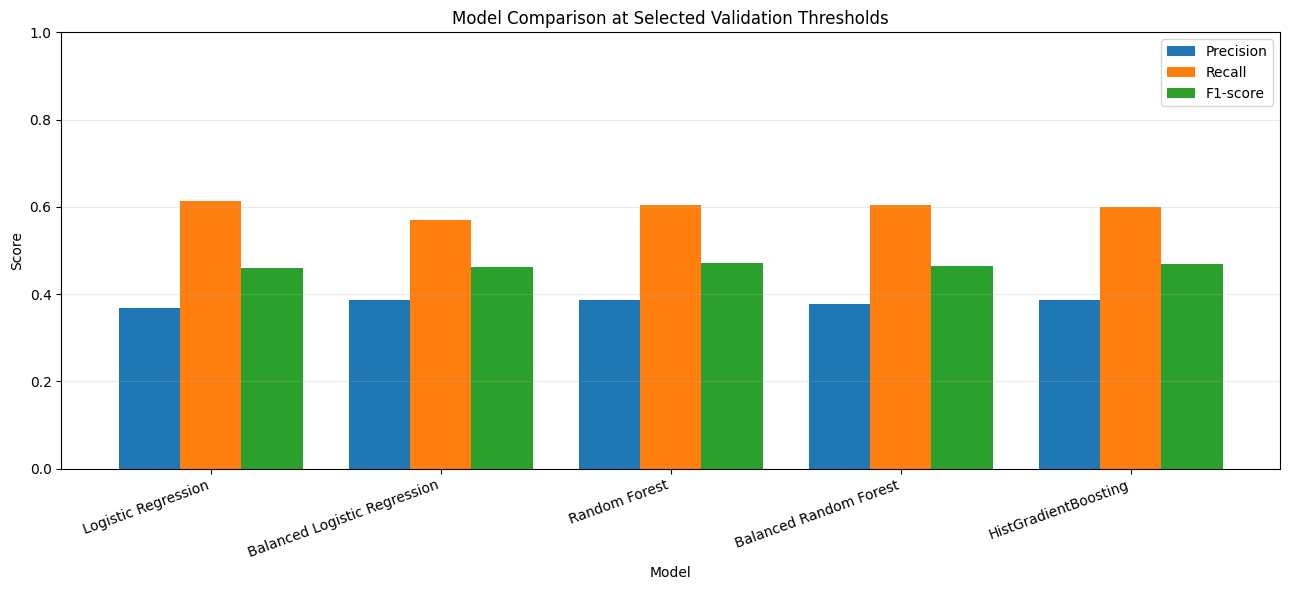

In [ ]:

# Step 15: Comparing all models at their selected validation thresholds

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

model_probabilities = {
    "Logistic Regression": prob_unbalanced,
    "Balanced Logistic Regression": prob_balanced,
    "Random Forest": y_val_prob_rf,
    "Balanced Random Forest": y_val_prob_rf_balanced,
    "HistGradientBoosting": y_val_prob_gb
}

# Best F1 thresholds
chosen_thresholds = {
    "Logistic Regression": 0.21,
    "Balanced Logistic Regression": 0.66,
    "Random Forest": 0.24,
    "Balanced Random Forest": 0.54,
    "HistGradientBoosting": 0.24
}

comparison_results = []

for name, probabilities in model_probabilities.items():
    threshold = chosen_thresholds[name]
    predictions = (probabilities >= threshold).astype(int)

    comparison_results.append({
        "Model": name,
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "Average Precision": average_precision_score(
            y_val, probabilities
        )
    })

model_comparison = pd.DataFrame(comparison_results)

print("MODEL COMPARISON — VALIDATION SET")
print(model_comparison.round(4).to_string(index=False))

# Visualise precision, recall and F1-score
plot_data = model_comparison.set_index("Model")[
    ["Precision", "Recall", "F1-score"]
]

ax = plot_data.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

ax.set_title("Model Comparison at Selected Validation Thresholds")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
ax.legend(loc="upper right")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


In [ ]:
#Saving the trained model for the dashboard

import joblib

model_bundle = {
    "model": final_model,
    "feature_names": X_train.columns.tolist(),
    "threshold": 0.24,
    "model_name": "Random Forest Classifier",
    "target_name": "Diabetes_binary"
}

joblib.dump(model_bundle, "/content/diabetes_random_forest.joblib")

print("Model saved successfully!")
print("Number of features:", len(model_bundle["feature_names"]))
print("Selected threshold:", model_bundle["threshold"])


Model saved successfully!
Number of features: 21
Selected threshold: 0.24


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sklearn
print(sklearn.__version__)

1.6.1


In [ ]:
import pandas as pd

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")

df: (253680, 23)
X: (253680, 21)
_7: (22, 3)
allcopies: (35575, 22)
X_train: (202944, 21)
X_test: (50736, 21)
X_train_fit: (162355, 21)
X_val: (40589, 21)
comparison: (4, 6)
comparison_df: (3, 9)
rf_balanced_results: (19, 4)
gb_threshold_df: (91, 4)
model_comparison: (5, 7)
plot_data: (5, 3)


In [ ]:

from google.colab import files

model_comparison.to_csv(
    "/content/model_comparison.csv",
    index=False
)

files.download("/content/model_comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(plot_data.columns.tolist())
display(plot_data)

['Precision', 'Recall', 'F1-score']


,Precision,Recall,F1-score
Model,,,
Logistic Regression,0.368098,0.614147,0.460305
Balanced Logistic Regression,0.386737,0.570292,0.460912
Random Forest,0.385953,0.604421,0.471091
Balanced Random Forest,0.377234,0.604775,0.464642
HistGradientBoosting,0.386221,0.598762,0.469560


In [ ]:
for name in [
    "y_test",
    "y_pred",
    "y_pred_proba",
    "y_test_proba",
    "final_model",
    "X_test"
]:
    if name in globals():
        obj = globals()[name]
        print(name, type(obj).__name__, getattr(obj, "shape", ""))

y_test Series (50736,)
final_model RandomForestClassifier 
X_test DataFrame (50736, 21)


In [ ]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

# Use the existing trained Random Forest
threshold = 0.24

# Predict probabilities for the positive class
y_test_proba = final_model.predict_proba(X_test)[:, 1]

# Convert probabilities into binary predictions
y_pred = (y_test_proba >= threshold).astype(int)

# Calculate evaluation results
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

print("\nROC-AUC:", round(
    roc_auc_score(y_test, y_test_proba), 4
))

print("Average Precision:", round(
    average_precision_score(y_test, y_test_proba), 4
))


Confusion Matrix:
[[36865  6802]
 [ 2896  4173]]

ROC-AUC: 0.8233
Average Precision: 0.4197
